In [5]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


In [3]:
def gremban_lift(L):
    """
    Constructs the Gremban expansion matrix M from a given matrix L.
    
    Args:
        L (numpy.ndarray): The input matrix (usually a Laplacian).
        
    Returns:
        numpy.ndarray: The 2n x 2n Gremban expansion matrix.
    """
    # Ensure input is a NumPy array
    L = np.array(L)
    
    # Get the size of the matrix (number of rows)
    n = L.shape[0]
    
    # Initialize a 2n x 2n matrix of zeros
    M = np.zeros((2 * n, 2 * n), dtype=float)

    for i in range(n):
        # Set diagonal elements for both diagonal blocks
        # Julia: M[i,i] and M[i+n,i+n]
        
        #M[i, i] = L[i, i]
        #M[i + n, i + n] = L[i, i]

        # Loop through the upper triangle (excluding diagonal)
        # Julia: for j in i+1:n
        Off_set_diag= 0
        for j in range(n):
            if j==i: 
                continue
            val = L[i, j]
            
            if val > 0:
                # "Bad" edges (positive off-diagonals) move to the off-diagonal blocks (A)
                # We negate the value as per the standard Gremban reduction
                M[i, n + j] = -val
                M[j, n + i] = -val
                M[n + i, j] = -val
                M[n + j, i] = -val
                Off_set_diag += val
                #print(f" sum is {Off_set_diag}, val is {val}")
            else:
                # "Good" edges (negative off-diagonals) stay in the diagonal blocks
                M[i, j] = val
                M[j, i] = val
                M[i + n, j + n] = val
                M[j + n, i + n] = val
                Off_set_diag += -val
                print(f" sum is{Off_set_diag}, val is {-val}")
        #print(f" round {i}, off is {Off_set_diag}")
        diff = L[i,i]-Off_set_diag
        M[i,i] = Off_set_diag+ diff/2
        M[i + n, i + n] = M[i, i]    
        M[i,i+n] =    -diff/2
        M[i+n,i] = -diff/2
    return M
    

In [56]:
def gremban_lift_hermitian(L,N_max):
    """
    Constructs the Gremban expansion matrix M from a given matrix L.
    
    Args:
        L (numpy.ndarray): The input matrix (usually a Laplacian).
        N_max: Size of the lift, depends on the 
        
    Returns:
        numpy.ndarray: The 2n x 2n Gremban expansion matrix.
    """
    # Ensure input is a NumPy array
    L = np.array(L)
    
    # Get the size of the matrix (number of rows)
    n = L.shape[0]
    
    # Initialize a 2n x 2n matrix of zeros
    M = np.zeros((N_max * n, N_max * n), dtype=float)

    for i in range(n):
        # Set diagonal elements for both diagonal blocks
        # Julia: M[i,i] and M[i+n,i+n]
        
        #M[i, i] = L[i, i]
        #M[i + n, i + n] = L[i, i]

        # Loop through the upper triangle (excluding diagonal)
        # Julia: for j in i+1:n
        Off_set_diag= 0
        for j in range(n):
            if j==i: 
                continue
            val = -L[i, j]
            for k in range(N_max):
               # print(np.exp(1j*2 * np.pi * k/N_max)*val)
                if np.isclose(np.exp(1j*2 * np.pi * k/N_max)*val,np.abs(val),atol=1e-7):
                    Off_set_diag += np.abs(val) 
                    for l in range(N_max): 
                     #   print(f"block index {k+l%N_max} and small index {j}")
                        M[n*l+i,n*((k+l)%N_max)+j]= -np.abs(val)
                        
        #print(f" round {i}, off is {Off_set_diag}")
        diff = L[i,i]-Off_set_diag
        for k in range(N_max):
            #print(f"accessing {n*k} with current value {M[n*k+i,n*k+i]}")
            M[n*k+i,n*k+i]=Off_set_diag+ diff/2   
            #print(f"changed {n*k+i} with current value {M[n*k+i,n*k+i]}")
            #print(f"block index {((int(N_max/2)+k)%N_max)} and small index {i} and runner {k} and step size {int(N_max/2)}")
            M[i+k*n,i+((int(N_max/2)+k)%N_max) *n] =    -diff/2
    return M

 sum is 1, val is 1
 sum is1, val is 0
 sum is1, val is 0
 sum is2, val is 1
 round 0, off is 2
 sum is 1, val is 1
 sum is1, val is 0
 sum is2, val is 1
 sum is3, val is 1
 round 1, off is 3
 sum is0, val is 0
 sum is0, val is 0
 sum is1, val is 1
 sum is2, val is 1
 round 2, off is 2
 sum is0, val is 0
 sum is1, val is 1
 sum is2, val is 1
 sum is 4, val is 2
 round 3, off is 4
 sum is1, val is 1
 sum is2, val is 1
 sum is3, val is 1
 sum is 5, val is 2
 round 4, off is 5
5


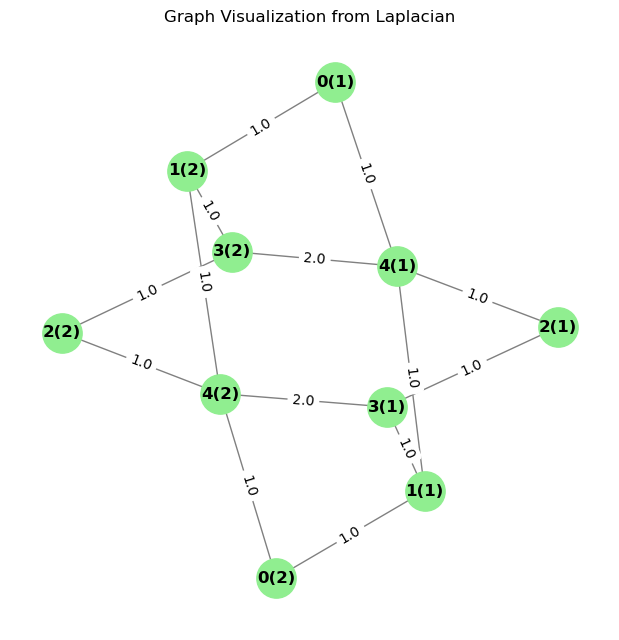

array([[ 2.,  0.,  0.,  0., -1.,  0., -1.,  0.,  0.,  0.],
       [ 0.,  3.,  0., -1., -1., -1.,  0.,  0.,  0.,  0.],
       [ 0.,  0.,  2., -1., -1.,  0.,  0.,  0.,  0.,  0.],
       [ 0., -1., -1.,  4.,  0.,  0.,  0.,  0.,  0., -2.],
       [-1., -1., -1.,  0.,  5.,  0.,  0.,  0., -2.,  0.],
       [ 0., -1.,  0.,  0.,  0.,  2.,  0.,  0.,  0., -1.],
       [-1.,  0.,  0.,  0.,  0.,  0.,  3.,  0., -1., -1.],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  2., -1., -1.],
       [ 0.,  0.,  0.,  0., -2.,  0., -1., -1.,  4.,  0.],
       [ 0.,  0.,  0., -2.,  0., -1., -1., -1.,  0.,  5.]])

In [454]:
test_SDD = [
    [ 2, 1,  0, 0,  -1],
    [1,  3, 0, -1,  -1],
    [ 0, 0, 2,  -1, -1],
    [ 0,  -1, -1, 4, 2],
    [ -1,  -1, -1, 2, 5],
]
lift_test= gremban_lift(test_SDD)
draw_graph_from_laplacian(lift_test,True)
lift_test


In [476]:
test_SDD = [
    [ 2, 1,  np.exp(1j*2*np.pi/4)],
    [1,  2, -1],
    [ -np.exp(1j*2*np.pi/4), -1, 2 ],
]
draw_graph_from_laplacian(test_SDD)

TypeError: float() argument must be a string or a real number, not 'complex'

<Figure size 600x600 with 0 Axes>

In [34]:
test_SDD = [
    [ 5, 1,  -2*np.exp(1j*2*np.pi/64),-2],
    [1,  3, -1,-np.exp(1j*2*np.pi/5)],
    [2* np.exp(1j*2*np.pi/64), -1, 6,-3],
    [-2,np.exp(1j*2*np.pi/5),-3,6]
]
lift_test= gremban_lift_hermitian(test_SDD,320)
#draw_graph_from_laplacian(lift_test,True,64)96
lift_test

 round 0, off is 5.0
accessing 0 with current value 0.0
changed 0 with current value 5.0
block index 160 and small index 0 and runner 0 and step size 160
accessing 4 with current value 0.0
changed 4 with current value 5.0
block index 161 and small index 0 and runner 1 and step size 160
accessing 8 with current value 0.0
changed 8 with current value 5.0
block index 162 and small index 0 and runner 2 and step size 160
accessing 12 with current value 0.0
changed 12 with current value 5.0
block index 163 and small index 0 and runner 3 and step size 160
accessing 16 with current value 0.0
changed 16 with current value 5.0
block index 164 and small index 0 and runner 4 and step size 160
accessing 20 with current value 0.0
changed 20 with current value 5.0
block index 165 and small index 0 and runner 5 and step size 160
accessing 24 with current value 0.0
changed 24 with current value 5.0
block index 166 and small index 0 and runner 6 and step size 160
accessing 28 with current value 0.0
chan

C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\788174388.py:47: ComplexWarning: Casting complex values to real discards the imaginary part
  M[n*k+i,n*k+i]=Off_set_diag+ diff/2
C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\788174388.py:50: ComplexWarning: Casting complex values to real discards the imaginary part
  M[i+k*n,i+((int(N_max/2)+k)%N_max) *n] =    -diff/2


array([[ 5.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  3., -1., ...,  0.,  0.,  0.],
       [ 0., -1.,  6., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ...,  3., -1.,  0.],
       [ 0.,  0.,  0., ..., -1.,  6., -3.],
       [ 0.,  0.,  0., ...,  0., -3.,  6.]])

In [35]:
p_inv_lift= np.linalg.pinv(lift_test)
"""
l_1=[0,0,1,0, -1,0,0,0, 0,0,0,0 ,0,0,0,0]
l_2=[-1,0,0,0, 0,0,0,0, 0,0,0,0, 0,0,1,0]
l_3=[0,0,0,0  ,0,0,0,0 ,0,0,1,0, -1,0,0,0]
l_4=[0,0,0,0  ,0,0,1,0, -1,0,0,0 ,0,0,0,0]

r_1= l_1@ p_inv_lift @ np.transpose(l_1)
r_2= l_2@ p_inv_lift @ np.transpose(l_2)
r_3= l_3@ p_inv_lift @ np.transpose(l_3)
r_4= l_4@ p_inv_lift @ np.transpose(l_4)
print(r_1,r_2,r_3,r_4)

r_12= l_1@ p_inv_lift @ np.transpose(l_2)
r_13= l_1@ p_inv_lift @ np.transpose(l_3)
r_14= l_1@ p_inv_lift @ np.transpose(l_4)
print(r_12,r_13,r_14)


r_21= l_2@ p_inv_lift @ np.transpose(l_1)
r_23= l_2@ p_inv_lift @ np.transpose(l_3)
r_24= l_2@ p_inv_lift @ np.transpose(l_4)
print(r_21,r_23,r_24)

r_31= l_3@ p_inv_lift @ np.transpose(l_1)
r_32= l_3@ p_inv_lift @ np.transpose(l_2)
r_34= l_3@ p_inv_lift @ np.transpose(l_4)
print(r_21,r_23,r_24)
"""




'\nl_1=[0,0,1,0, -1,0,0,0, 0,0,0,0 ,0,0,0,0]\nl_2=[-1,0,0,0, 0,0,0,0, 0,0,0,0, 0,0,1,0]\nl_3=[0,0,0,0  ,0,0,0,0 ,0,0,1,0, -1,0,0,0]\nl_4=[0,0,0,0  ,0,0,1,0, -1,0,0,0 ,0,0,0,0]\n\nr_1= l_1@ p_inv_lift @ np.transpose(l_1)\nr_2= l_2@ p_inv_lift @ np.transpose(l_2)\nr_3= l_3@ p_inv_lift @ np.transpose(l_3)\nr_4= l_4@ p_inv_lift @ np.transpose(l_4)\nprint(r_1,r_2,r_3,r_4)\n\nr_12= l_1@ p_inv_lift @ np.transpose(l_2)\nr_13= l_1@ p_inv_lift @ np.transpose(l_3)\nr_14= l_1@ p_inv_lift @ np.transpose(l_4)\nprint(r_12,r_13,r_14)\n\n\nr_21= l_2@ p_inv_lift @ np.transpose(l_1)\nr_23= l_2@ p_inv_lift @ np.transpose(l_3)\nr_24= l_2@ p_inv_lift @ np.transpose(l_4)\nprint(r_21,r_23,r_24)\n\nr_31= l_3@ p_inv_lift @ np.transpose(l_1)\nr_32= l_3@ p_inv_lift @ np.transpose(l_2)\nr_34= l_3@ p_inv_lift @ np.transpose(l_4)\nprint(r_21,r_23,r_24)\n'

In [20]:
def l_tilde_construct(l,N):
    l_size=l.shape[0]
    print(l_size)
    l_tilde= np.zeros(l_size*N,dtype=complex)
    for i in range(N):
        print()
        l_tilde[i*l_size:(i+1)*l_size]= np.exp(1j*2*np.pi*i/N)*l
    return l_tilde

In [43]:
def deconstruct_l_matr(l_to_decon,N,a,b,k):
    l_size= l_to_decon.shape[0]
    l_tilde_size= int(l_size*N)
    matrix_deconstruct= np.zeros([l_tilde_size,N],dtype=complex)
    for i in range(N):
        b_i= np.zeros(l_tilde_size,dtype=complex)
        b_i[i*l_size+a]= 1
        #print(f"index {i} postion{(i+k)%N*l_size}")
        b_i[(i+k)%N*l_size+b]=-1
        matrix_deconstruct[:,i] = b_i
    return matrix_deconstruct

In [49]:


def eff_ref_and_trans_imb_matr(lift,l_new,N_max,a,b,phi_k):
    pinv_lift= np.linalg.pinv(lift)
    b_matrix= deconstruct_l_matr(l_new,N_max,a,b,phi_k)
    print(b_matrix.shape)
    zero_total =0
    total_eff_ref=0
    r_eff_matrix= np.transpose(b_matrix)@pinv_lift@ b_matrix
    for i in range(b_matrix.shape[1]):
        for j in range(i):
            trans_imb= r_eff_matrix[i,j]
            zero_total+= 2 * np.cos(2*np.pi *(j-i)/N_max)* trans_imb
    
    total_eff_ref= np.sum(r_eff_matrix.diagonal())       
    print(f"zero total impedenance is  {zero_total}")
    print(f"total eff ref is {total_eff_ref}")
    return total_eff_ref,zero_total


In [79]:

a=49
b=43
r_a= 1205.0663694266173
r_b= -1827.4887270145014
l_new=np.array([1,0,0,np.exp(1j*2*np.pi/a)])
N_max= np.lcm(a,b)
test_SDD = [
    [ np.abs(r_a)+2, 0,  -r_a*np.exp(1j*2*np.pi/a),-2],
    [0,   np.abs(r_b)+1, -1,-43*np.exp(1j*2*np.pi/b)],
    [r_a* np.exp(1j*2*np.pi/a), -1, np.abs(r_a)+4,-3],
    [-2,0.43*np.exp(1j*2*np.pi/b),-3,np.abs(r_b)+5]
]
lift_test= gremban_lift_hermitian(test_SDD,N_max)
new_tot_reff, new_total_trans_imb= eff_ref_and_trans_imb_matr(lift_test,l_new,N_max,0,3,b)

C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\811304655.py:47: ComplexWarning: Casting complex values to real discards the imaginary part
  M[n*k+i,n*k+i]=Off_set_diag+ diff/2
C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\811304655.py:50: ComplexWarning: Casting complex values to real discards the imaginary part
  M[i+k*n,i+((int(N_max/2)+k)%N_max) *n] =    -diff/2


MemoryError: Unable to allocate 542. MiB for an array with shape (8428, 8428) and data type float64

In [ ]:
import random
for i in range(1000): 
    r_a = (np.random.rand() - 0.5) * 10000  # scalar
    r_b = (np.random.rand() - 0.5) * 10000  # scalar
    phi_a = random.randint(0,50)
    phi_b = random.randint(0,50)
    l_new=np.array([1,0,0,np.exp(1j*2*np.pi/a)])
    N_max= np.lcm(phi_a,phi_b)
    test_SDD_rand = [
    [ 2+np.abs(r_a), 0,  -r_a*np.exp(1j*2*np.pi/phi_a),-2],
    [0,  1+np.abs(r_b), -1,-r_b*np.exp(1j*2*np.pi/phi_b)],
    [r_a * np.exp(1j*2*np.pi/phi_a), -1, 4+np.abs(r_a),-3],
    [-2,r_b*np.exp(1j*2*np.pi/phi_b),-3,5+np.abs(r_b)]
    ]
    lift_rand= gremban_lift_hermitian(test_SDD_rand,N_max)
    new_tot_reff, new_total_trans_imb= eff_ref_and_trans_imb_matr(lift_rand,l_new,N_max,0,3,phi_b)
    print(new_tot_reff,new_total_trans_imb,phi_a,phi_b,r_a,r_b)
    if np.abs(new_total_trans_imb)>=new_tot_reff:
        print(r_a,r_b,phi_a,phi_b)
        break




C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\811304655.py:47: ComplexWarning: Casting complex values to real discards the imaginary part
  M[n*k+i,n*k+i]=Off_set_diag+ diff/2
C:\Users\alex1\AppData\Local\Temp\ipykernel_27204\811304655.py:50: ComplexWarning: Casting complex values to real discards the imaginary part
  M[i+k*n,i+((int(N_max/2)+k)%N_max) *n] =    -diff/2


(840, 210)
zero total impedenance is  (-5.590009563200949+0j)
total eff ref is (6.800641649711267+0j)
(6.800641649711267+0j) (-5.590009563200949+0j)
(1472, 368)
zero total impedenance is  (-7.9709157394863785+0j)
total eff ref is (13.832700070479648+0j)
(13.832700070479648+0j) (-7.9709157394863785+0j)
(8428, 2107)
zero total impedenance is  0j
total eff ref is 0j
0j 0j
1205.0663694266173 -1827.4887270145014 49 43


In [76]:
test_array=np.array( [r_a * np.exp(1j*2*np.pi/phi_a), -1, 4+np.abs(r_a),-3],dtype=complex)
print(test_array.shape)

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (4,) + inhomogeneous part.

In [572]:
l=np.array([1,0,0,-1])
l_tild= l_tilde_construct(l,32)
l_tild
b_list= deconstruct_l(l,32,0,3,1)


4
































index 0 postion4
index 1 postion8
index 2 postion12
index 3 postion16
index 4 postion20
index 5 postion24
index 6 postion28
index 7 postion32
index 8 postion36
index 9 postion40
index 10 postion44
index 11 postion48
index 12 postion52
index 13 postion56
index 14 postion60
index 15 postion64
index 16 postion68
index 17 postion72
index 18 postion76
index 19 postion80
index 20 postion84
index 21 postion88
index 22 postion92
index 23 postion96
index 24 postion100
index 25 postion104
index 26 postion108
index 27 postion112
index 28 postion116
index 29 postion120
index 30 postion124
index 31 postion0


In [36]:
l_new=np.array([1,0,0,1j])
N_max= 320
b_list= deconstruct_l(l_new,N_max,0,3,5)
print(len(b_list))
zero_total =0
total_eff_ref=0
for i in range(len(b_list)):
    i_set_off = 0
    
    for j in range(len(b_list)):
        if i != j: 
            trans_imb = b_list[i]@ p_inv_lift@ np.transpose(b_list[j])
            i_set_off += np.abs(trans_imb)
            if i<j: 
                zero_total+= 2 * np.cos(2*np.pi *(j-i)/N_max)* trans_imb
        #print(f"index i is {i}, index j is {j} and transfer impendance {trans_imb}")
        else:
            eff_ref= b_list[i]@ p_inv_lift@ np.transpose(b_list[i])
            #print(f"effective resistance is {eff_ref}")
            total_eff_ref+= eff_ref
print(f"zero total impedenance is  {zero_total}")
print(f"total eff ref is {total_eff_ref}")


320
effective resistance is (0.5229408151473856+0j)
effective resistance is (0.5229408151473867+0j)
effective resistance is (0.5229408151473852+0j)
effective resistance is (0.5229408151473861+0j)
effective resistance is (0.5229408151473849+0j)
effective resistance is (0.5229408151473857+0j)
effective resistance is (0.5229408151473844+0j)
effective resistance is (0.5229408151473844+0j)
effective resistance is (0.5229408151473857+0j)
effective resistance is (0.5229408151473858+0j)
effective resistance is (0.5229408151473857+0j)
effective resistance is (0.522940815147386+0j)
effective resistance is (0.5229408151473853+0j)
effective resistance is (0.5229408151473849+0j)
effective resistance is (0.5229408151473858+0j)
effective resistance is (0.5229408151473862+0j)
effective resistance is (0.5229408151473847+0j)
effective resistance is (0.5229408151473858+0j)
effective resistance is (0.5229408151473875+0j)
effective resistance is (0.5229408151473864+0j)
effective resistance is (0.5229408151

In [1]:
S=[[2,-1,-1],
   [-1,2,1],
   [-1,1,-2],]

In [ ]:
import numpy as np 
S_pinv= np.linalg.pinv(S)
l=[]

In [30]:
l_new=np.array([1,0,0,1j])
b_list= deconstruct_l(l_new,160,0,3,5)
print(len(b_list))
for i in range(len(b_list)):
    i_set_off = 0
    for j in range(len(b_list)):
        if i != j: 
            trans_imb = b_list[i]@ p_inv_lift@ np.transpose(b_list[j])
            i_set_off += np.abs(trans_imb)
            #print(f"index i is {i}, index j is {j} and transfer impendance {trans_imb}")
    print(f"effective resistance is {b_list[i]@ p_inv_lift@ np.transpose(b_list[i])} and sum transfer imbedance is {i_set_off}")

160
effective resistance is (0.5229481279306777+0j) and sum transfer imbedance is 0.9077547699584061
effective resistance is (0.5229481279306769+0j) and sum transfer imbedance is 0.9077547699584055
effective resistance is (0.5229481279306769+0j) and sum transfer imbedance is 0.9077547699584039
effective resistance is (0.5229481279306767+0j) and sum transfer imbedance is 0.907754769958403
effective resistance is (0.5229481279306775+0j) and sum transfer imbedance is 0.9077547699584051
effective resistance is (0.5229481279306776+0j) and sum transfer imbedance is 0.9077547699584056
effective resistance is (0.5229481279306771+0j) and sum transfer imbedance is 0.9077547699584032
effective resistance is (0.5229481279306769+0j) and sum transfer imbedance is 0.9077547699584021
effective resistance is (0.5229481279306775+0j) and sum transfer imbedance is 0.9077547699584025
effective resistance is (0.5229481279306774+0j) and sum transfer imbedance is 0.9077547699584031
effective resistance is (0.

KeyboardInterrupt: 

In [ ]:
l_new=np.array([1,0,0,1j])
b_list= deconstruct_l(l_new,800,0,3,1)
print(len(b_list))
for i in range(len(b_list)):
    i_set_off = 0
    for j in range(len(b_list)):
        if i != j: 
            trans_imb = b_list[i]@ p_inv_lift@ np.transpose(b_list[j])
            i_set_off += np.abs(trans_imb)
            #print(f"index i is {i}, index j is {j} and transfer impendance {trans_imb}")
    print(f"effective resistance is {b_list[i]@ p_inv_lift@ np.transpose(b_list[i])} and sum transfer imbedance is {i_set_off}")

index 0 postion4
index 1 postion8
index 2 postion12
index 3 postion16
index 4 postion20
index 5 postion24
index 6 postion28
index 7 postion32
index 8 postion36
index 9 postion40
index 10 postion44
index 11 postion48
index 12 postion52
index 13 postion56
index 14 postion60
index 15 postion64
index 16 postion68
index 17 postion72
index 18 postion76
index 19 postion80
index 20 postion84
index 21 postion88
index 22 postion92
index 23 postion96
index 24 postion100
index 25 postion104
index 26 postion108
index 27 postion112
index 28 postion116
index 29 postion120
index 30 postion124
index 31 postion128
index 32 postion132
index 33 postion136
index 34 postion140
index 35 postion144
index 36 postion148
index 37 postion152
index 38 postion156
index 39 postion160
index 40 postion164
index 41 postion168
index 42 postion172
index 43 postion176
index 44 postion180
index 45 postion184
index 46 postion188
index 47 postion192
index 48 postion196
index 49 postion200
index 50 postion204
index 51 postion

In [558]:
l_new=np.array([1,0,0,1j])
b_list= deconstruct_l(l_new,16,0,3,1)
print(len(b_list))
for i in range(len(b_list)):
    print(f"index i is {i}, index j is {i} and effective restistance is {b_list[i]@ p_inv_lift@ np.transpose(b_list[i])}")

index 0 postion4
index 1 postion8
index 2 postion12
index 3 postion16
index 4 postion20
index 5 postion24
index 6 postion28
index 7 postion32
index 8 postion36
index 9 postion40
index 10 postion44
index 11 postion48
index 12 postion52
index 13 postion56
index 14 postion60
index 15 postion0
16
index i is 0, index j is 0 and effective restistance is (0.7257788211669101+0j)
index i is 1, index j is 1 and effective restistance is (0.7257788211669105+0j)
index i is 2, index j is 2 and effective restistance is (0.7257788211669103+0j)
index i is 3, index j is 3 and effective restistance is (0.7257788211669096+0j)
index i is 4, index j is 4 and effective restistance is (0.7257788211669104+0j)
index i is 5, index j is 5 and effective restistance is (0.7257788211669087+0j)
index i is 6, index j is 6 and effective restistance is (0.7257788211669098+0j)
index i is 7, index j is 7 and effective restistance is (0.7257788211669103+0j)
index i is 8, index j is 8 and effective restistance is (0.7257788

In [537]:
for i in range(len(b_list)):
    for j in range(len(b_list)):
        print(f"index i is {i}, index j is {j} and transfer impendance {b_list[i]@ p_inv_lift@ np.transpose(b_list[j])}")

index i is 0, index j is 0 and transfer impendance (0.7922618001844256+0j)
index i is 0, index j is 1 and transfer impendance (-0.342180732547121+0j)
index i is 0, index j is 2 and transfer impendance (0.0008444404614654025+0j)
index i is 0, index j is 3 and transfer impendance (0.0011994533342373562+0j)
index i is 1, index j is 0 and transfer impendance (-0.09295472543824607+0j)
index i is 1, index j is 1 and transfer impendance (0.7922618001844275+0j)
index i is 1, index j is 2 and transfer impendance (-0.3421807325471219+0j)
index i is 1, index j is 3 and transfer impendance (0.0008444404614656315+0j)
index i is 2, index j is 0 and transfer impendance (-0.06239906618220825+0j)
index i is 2, index j is 1 and transfer impendance (-0.09295472543824658+0j)
index i is 2, index j is 2 and transfer impendance (0.7922618001844252+0j)
index i is 2, index j is 3 and transfer impendance (-0.3421807325471201+0j)
index i is 3, index j is 0 and transfer impendance (0.010293776060753428+0j)
index 

In [23]:
def deconstruct_l(l_to_decon,N,a,b,k):
    l_size= l_to_decon.shape[0]
    l_tilde_size= int(l_size*N)
    b_list=[]
    for i in range(N):
        b_i= np.zeros(l_tilde_size,dtype=complex)
        b_i[i*l_size+a]= 1
        #print(f"index {i} postion{(i+k)%N*l_size}")
        b_i[(i+k)%N*l_size+b]=-1
        b_list.append(b_i)
    return b_list



In [7]:

def draw_graph_from_laplacian(laplacian_matrix, is_lift=False,lift_size=2):
    """
    Parses a Laplacian matrix and draws the corresponding graph.
    """
    # 1. Convert input to a Numpy array
    L = np.array(laplacian_matrix)
    
    # Check if the matrix is square
    if L.shape[0] != L.shape[1]:
        raise ValueError("Matrix must be square.")

    # 2. Reconstruct the Adjacency Matrix (A)
    # Since L = D - A, then A = -L (for off-diagonal elements)
    adj_matrix = -L
    
    # Set the diagonal to 0 (assuming a simple graph with no self-loops)
    np.fill_diagonal(adj_matrix, 0)
    
    # Replace negative values with 0 (just a safeguard against bad input)
    adj_matrix[adj_matrix < 0] = 0

    # 3. Create the graph using NetworkX
    # This automatically handles weights if the Laplacian values are not just -1
    G = nx.from_numpy_array(adj_matrix)

    # 4. Draw the graph
    plt.figure(figsize=(6, 6))
    
    # Use a spring layout to space nodes out naturally
    pos = nx.spring_layout(G) 
    
    # Draw nodes, edges, and labels
    if is_lift: 
        n= L.shape[0]/lift_size
        label_list=[f"{int(i% n)}({int(i// n)})" for i in range(L.shape[0]) ]
        labels_map = {i: name for i, name in enumerate(label_list)}
        nx.draw(G, pos, 
            labels=labels_map,  # Pass the dictionary here
            with_labels=True,   # Ensure this is True
            node_color='lightgreen', 
            edge_color='gray', 
            node_size=800, 
            font_size=12,
            font_weight='bold')
    else:
        nx.draw(G, pos, 
                with_labels=True, 
                node_color='lightblue', 
                edge_color='gray', 
                node_size=700, 
                font_size=12,
                width=2) # Line width of edges
            
    # Draw edge labels (weights) if the graph is weighted
    edge_labels = nx.get_edge_attributes(G, "weight")
    # Only draw weights if they are not all 1 (unweighted standard graph)
    if any(w != 1 for w in edge_labels.values()):
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

    plt.title("Graph Visualization from Laplacian")
    plt.axis("off")
    plt.show()



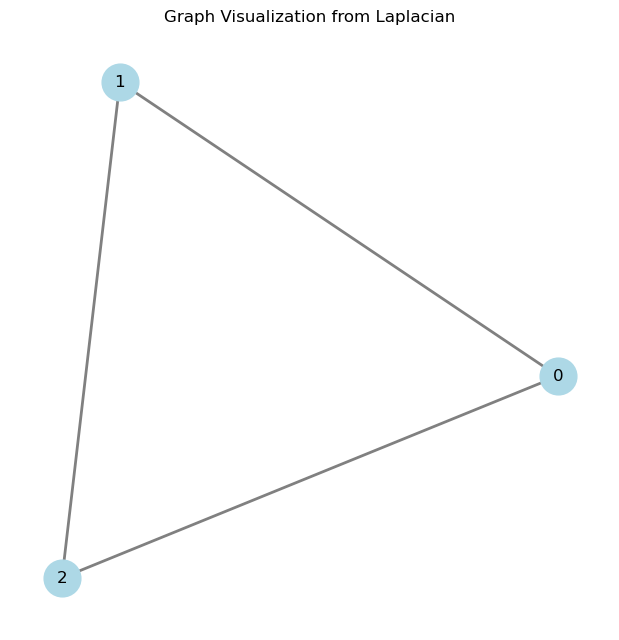

In [4]:
# --- Example Usage ---

# Example: A simple Triangle Graph (K3)
# Degrees are 2, edges are -1
triangle_laplacian = [
    [ 2, -1, -1],
    [-1,  2, -1],
    [-1, -1,  2]
]


# Run the function with the path example
draw_graph_from_laplacian(triangle_laplacian)

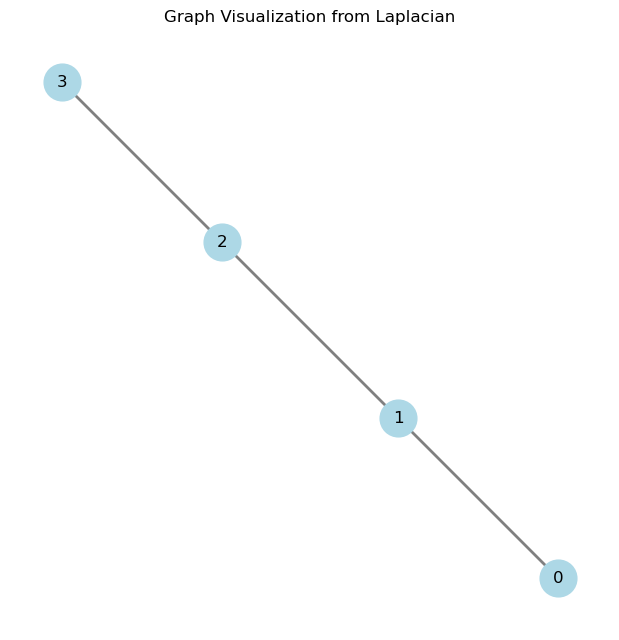

In [5]:
# Example: A path graph 0-1-2-3
path_laplacian = [
    [ 1, -1,  0,  0],
    [-1,  2, -1,  0],
    [ 0, -1,  2, -1],
    [ 0,  0, -1,  1]
]

# Run the function with the path example
draw_graph_from_laplacian(path_laplacian)

In [66]:
L_proper= [
    [2,-1,0,-1],
    [-1,2,-1,0],
    [0,-1,2,-1],
    [-1,0,-1,2],
]
L_self= [
    [2,-1,-1,0],
    [-1,2,0,-1],
    [-1,0,2,-1],
    [0,-1,-1,2],
]
L_pinv= np.linalg.pinv(L_self)
L_pinv

array([[ 0.3125, -0.0625, -0.0625, -0.1875],
       [-0.0625,  0.3125, -0.1875, -0.0625],
       [-0.0625, -0.1875,  0.3125, -0.0625],
       [-0.1875, -0.0625, -0.0625,  0.3125]])

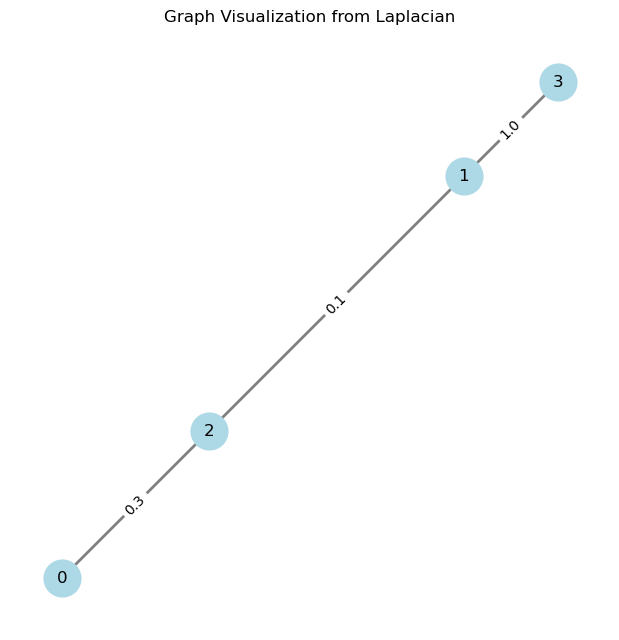

In [14]:
ssd_fml=  [
    [1.3, 0, -0.3,1],
    [0,1.1,-0.1,-1],
    [-0.3,-0.1,0.4,0],
    [1, -1, 0,2],
]
draw_graph_from_laplacian(ssd_fml)

In [16]:
ssd_fml=  [
    [1.3, 0, -0.3,1],
    [0,1.1,-0.1,-1],
    [-0.3,-0.1,0.4,0],
    [1, -1, 0,2],
]
lift_fml= gremban_lift(ssd_fml)
lift_fml



 sum is0.0, val is -0.0
 sum is0.3, val is 0.3
 sum is0.0, val is -0.0
 sum is0.1, val is 0.1
 sum is1.1, val is 1.0
 sum is0.3, val is 0.3
 sum is0.4, val is 0.1
 sum is0.4, val is -0.0
 sum is2.0, val is 1.0
 sum is2.0, val is -0.0


array([[ 1.3,  0. , -0.3,  0. , -0. ,  0. ,  0. , -1. ],
       [ 0. ,  1.1, -0.1, -1. ,  0. , -0. ,  0. ,  0. ],
       [-0.3, -0.1,  0.4,  0. ,  0. ,  0. , -0. ,  0. ],
       [ 0. , -1. ,  0. ,  2. , -1. ,  0. ,  0. , -0. ],
       [-0. ,  0. ,  0. , -1. ,  1.3,  0. , -0.3,  0. ],
       [ 0. , -0. ,  0. ,  0. ,  0. ,  1.1, -0.1, -1. ],
       [ 0. ,  0. , -0. ,  0. , -0.3, -0.1,  0.4,  0. ],
       [-1. ,  0. ,  0. , -0. ,  0. , -1. ,  0. ,  2. ]])

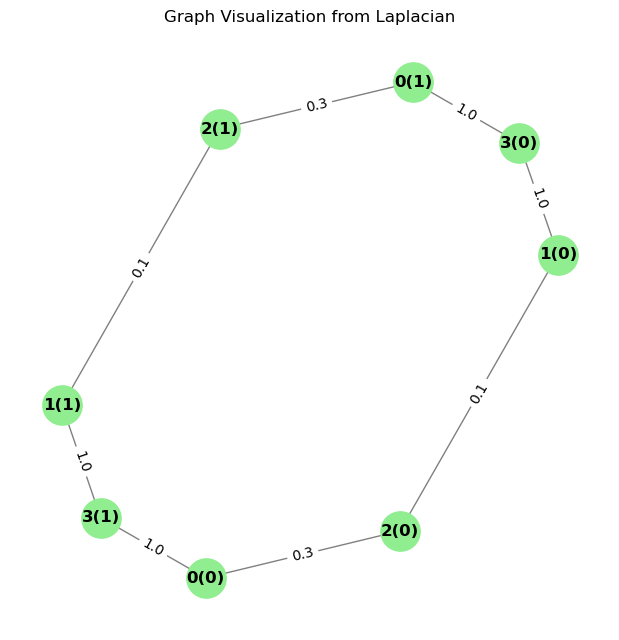

In [15]:
draw_graph_from_laplacian(lift_fml,True, 2)

In [13]:
l= [1,0,-1,0,0,0,0,0]
pinv_fml= np.linalg.pinv(lift_fml)
r_l=0.3*(l @ pinv_fml @ np.transpose(l))
r_l

np.float64(0.891304347826087)

4


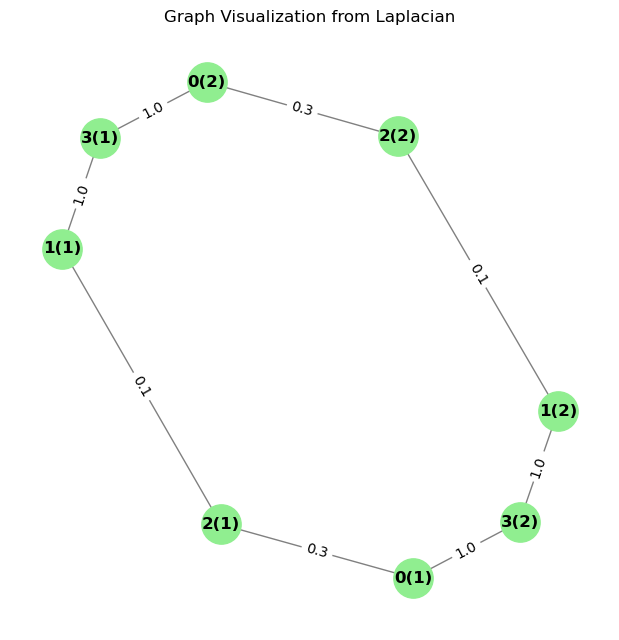

In [360]:
draw_graph_from_laplacian(lift_fml,True)

In [563]:
L_Pinv_new= np.linalg.pinv(lift_fml)
L_Pinv_new

array([[ 2.17685688, -1.53691123,  0.93591486, -1.65919384, -1.65647645,
         1.2964221 , -1.23075181,  1.67413949],
       [-1.53691123,  2.28555254, -0.89379529,  1.72848732,  1.2964221 ,
        -1.5477808 ,  0.27287138, -1.60484601],
       [ 0.93591486, -0.89379529,  2.66598732, -1.12477355, -1.23075181,
         0.27287138, -1.16734601,  0.54189312],
       [-1.65919384,  1.72848732, -1.12477355,  2.13881341,  1.67413949,
        -1.60484601,  0.54189312, -1.69451993],
       [-1.65647645,  1.2964221 , -1.23075181,  1.67413949,  2.17685688,
        -1.53691123,  0.93591486, -1.65919384],
       [ 1.2964221 , -1.5477808 ,  0.27287138, -1.60484601, -1.53691123,
         2.28555254, -0.89379529,  1.72848732],
       [-1.23075181,  0.27287138, -1.16734601,  0.54189312,  0.93591486,
        -0.89379529,  2.66598732, -1.12477355],
       [ 1.67413949, -1.60484601,  0.54189312, -1.69451993, -1.65919384,
         1.72848732, -1.12477355,  2.13881341]])

In [210]:
L_Pinv_new= [[ 5.55555556e-01,  3.32942482e-17, -1.11111111e-01,
        -1.04140107e-16, -4.44444444e-01,  8.31496163e-17],
       [ 4.48463232e-17,  5.55555556e-01,  4.33329179e-17,
        -4.44444444e-01, -1.49304937e-16, -1.11111111e-01],
       [-1.11111111e-01,  9.96359259e-17,  2.22222222e-01,
        -1.08179714e-16, -1.11111111e-01,  1.08139974e-17],
       [-1.95320530e-17, -4.44444444e-01, -3.26498806e-18,
         5.55555556e-01,  1.77622853e-16, -1.11111111e-01],
       [-4.44444444e-01,  2.37816414e-16, -1.11111111e-01,
        -1.58519830e-16,  5.55555556e-01, -9.38705510e-17],
       [-6.45665817e-17, -1.11111111e-01, -4.00679298e-17,
        -1.11111111e-01,  1.09343954e-17,  2.22222222e-01]]

In [564]:
l= [1,-1,0,0,-1,1,0,0]
#print(L_Pinv.shape)
r_l= np.transpose(l)@L_Pinv_new@ l
r_l

np.float64(26.66666666666665)

In [565]:
l_1= [1,-1,0,0,0,0,0,0]
r_1=  np.transpose(l_1)@L_Pinv_new@ l_1
r_1

np.float64(7.536231884057969)

In [566]:
e_1= [0,0,0,0,-1,1,0,0]
re_1= 1* np.transpose(e_1)@L_Pinv_new@ e_1
re_1

np.float64(7.536231884057963)

In [567]:
e_2= [0,1,-1,0,0,0,0,0]
re_2=0.1*  np.transpose(e_2)@L_Pinv_new@ e_2
re_2

np.float64(0.673913043478261)

In [568]:
l_2= [0,0,0,0,-1,1,0,0]
r_2= np.transpose(l_2)@L_Pinv_new@ l_2
r_2

np.float64(7.536231884057963)

In [569]:
r_12= np.transpose(l_2)@L_Pinv_new@ l_1
r_12

np.float64(5.797101449275358)

In [400]:
r_12/r_2

np.float64(0.7692307692307695)

In [403]:
(0.891* 0.1+ 0.3*0.67)/(0.4)

0.7252500000000001

In [404]:
0.725*1.77

1.28325

In [392]:
flow_1= L_Pinv_new@ l_1
flow_1

array([ 1.24094203, -0.64311594, -1.73007246, -0.53442029, -0.42572464,
        1.02355072, -0.0634058 ,  1.13224638])